# Lab 04 - Acquisition functions and Bayesian optimization
## Tasks
- Demonstrate Bayesian optimization
- Solve quadrupole triplet focusing using Bayesian optimization

# Set up environment

In [6]:
%matplotlib inline

In [1]:
%reset -f
!pip install botorch==0.12.0 gpytorch xopt==2.5.2 -q
!pip install cheetah-accelerator -q


[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: pip install --upgrade pip

[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: pip install --upgrade pip


In [2]:
import numpy as np
import matplotlib.pyplot as plt

#import packages required for BO
import torch

from botorch.models import SingleTaskGP
from botorch.models.transforms import Normalize, Standardize
from botorch.fit import fit_gpytorch_mll
from botorch.acquisition import LogExpectedImprovement
from gpytorch.mlls import ExactMarginalLogLikelihood

## GP model creation
We start by generating two random observations to create the initial GP model (using BoTorch this time). Note that BoTorch does a number of things under the hood, including using Normalization and Standardization transformers to normalize and standardize the data.

In [3]:
def f(x):
    return torch.sin(2*torch.pi*x) + x + torch.randn_like(x) * 0.01

train_x = torch.tensor([0.3,0.5],dtype=torch.double).unsqueeze(-1)
train_y = f(train_x)

gp = SingleTaskGP(
    train_X=train_x,
    train_Y=train_y,
    input_transform=Normalize(d=1),
    outcome_transform=Standardize(m=1),
)
mll = ExactMarginalLogLikelihood(gp.likelihood, gp)
fit_gpytorch_mll(mll);

### Acquisition function definition
Next we define the acquisition function. For this example we use Log Expected Improvement (EI).

In [4]:
acquisition_function = LogExpectedImprovement(gp, best_f=torch.max(train_y))

### Visualize the GP model and the acquisition function.

Text(0, 0.5, '$\\alpha(x)$')

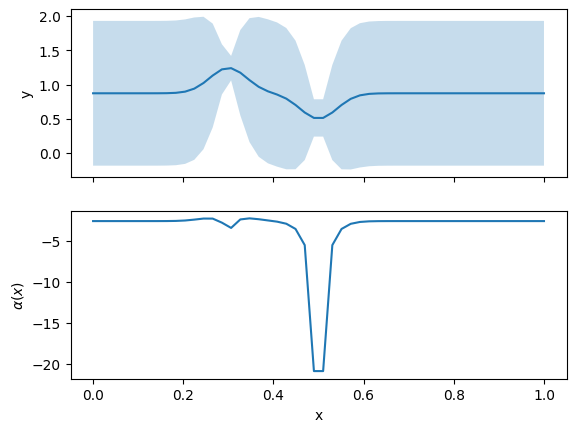

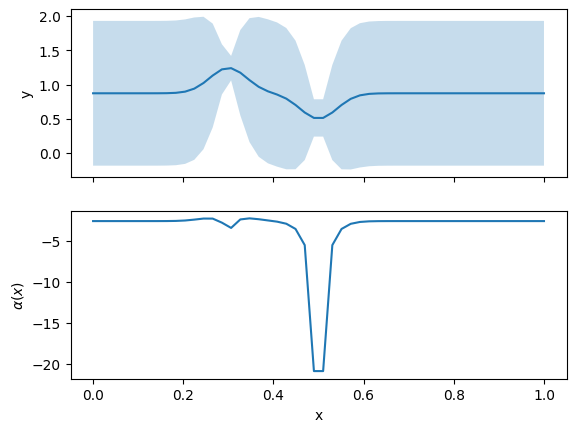

In [7]:
x = torch.linspace(0, 1, 50)
with torch.no_grad():
    p = gp.posterior(x.reshape(-1,1,1))

    #get the mean
    m = p.mean.squeeze()

    #get the 2 sigma confidence region around the mean
    l,u = p.mvn.confidence_region()
    l = l.squeeze()
    u = u.squeeze()

    # calculate the acquisition function
    acqf = acquisition_function(x.reshape(-1,1,1))


fig,ax = plt.subplots(2,1,sharex=True)
ax[1].set_xlabel('x')
ax[0].set_ylabel('y')
#plot mean and confidence region
ax[0].plot(x, m)
ax[0].fill_between(x.squeeze(), l, u, alpha = 0.25, lw = 0)

ax[1].plot(x, acqf)
ax[1].set_ylabel(r"$\alpha(x)$")


### Optimize the acquisition function
Use the `optimize_acqf` function in BoTorch to maximize the acquisition function.

In [8]:
from botorch.optim import optimize_acqf

bounds = torch.stack([torch.zeros(1), torch.ones(1)]).to(torch.double)
candidate, acq_value = optimize_acqf(
    acquisition_function, bounds=bounds, q=1, num_restarts=5, raw_samples=20,
)
candidate

tensor([[0.3441]], dtype=torch.float64)

# Basic BO
We are going to maximize the following function using Bayesian optimization

$$
f(x) = \sin(2\pi x) + x
$$
in the domain $[0,1]$.

### **Task**
Perform 20 steps of BO to solve the optimization problem. Plot the model and the acquisition function at the end of each optimization step.

candidate: 0.24144114620817828 observation: 1.2351288840623331


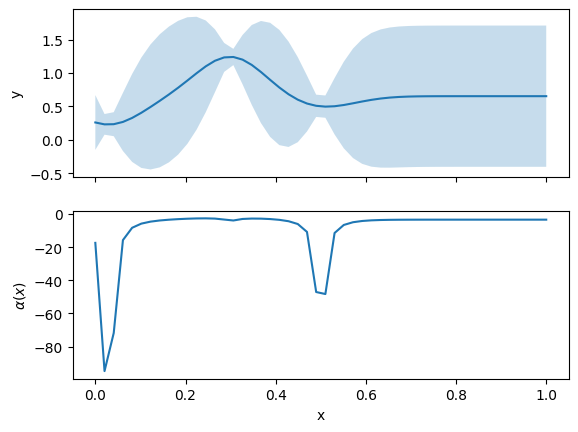

candidate: 1.0 observation: 1.010822159304012


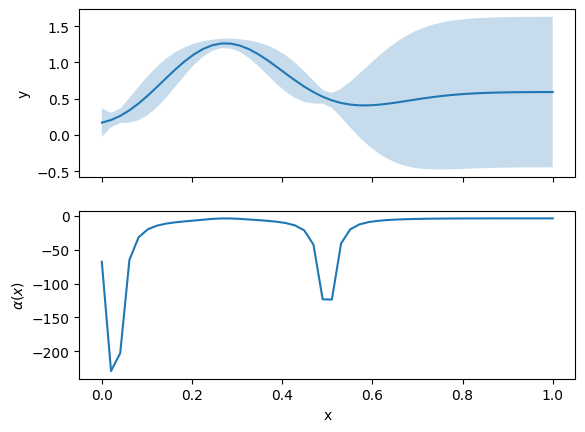

candidate: 0.8377070173278937 observation: -0.027602993447128486


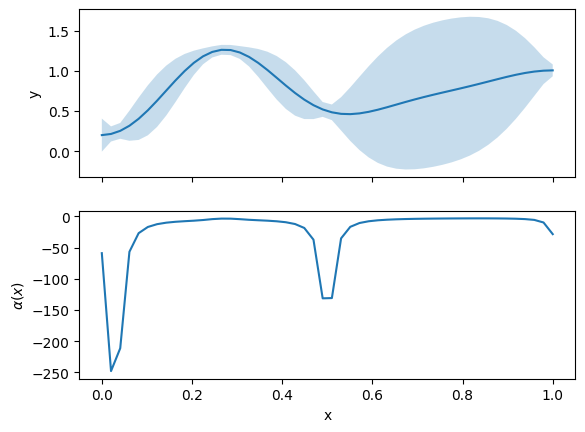

candidate: 0.2725605570344902 observation: 1.2702478067416678


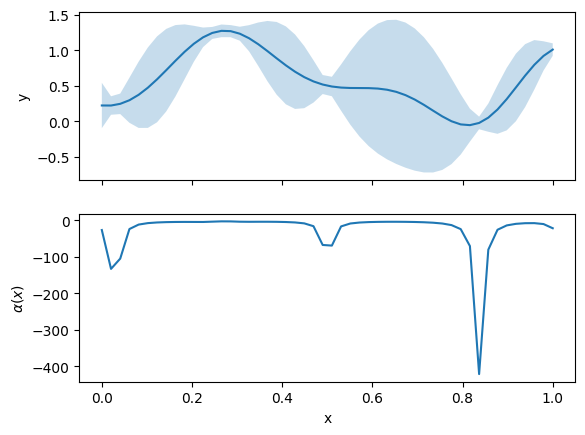

candidate: 0.27322985555147317 observation: 1.2606173717920552


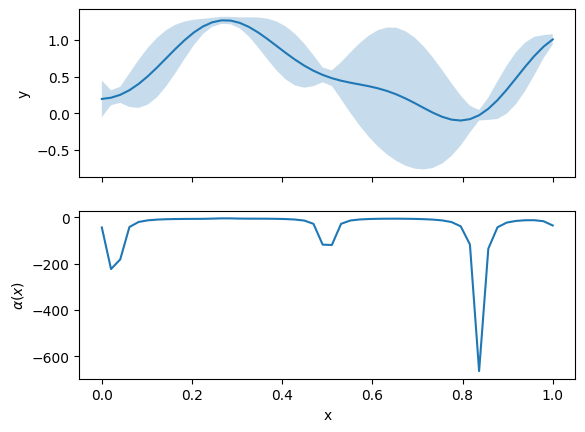

candidate: 0.27335926213921813 observation: 1.2624968812622088


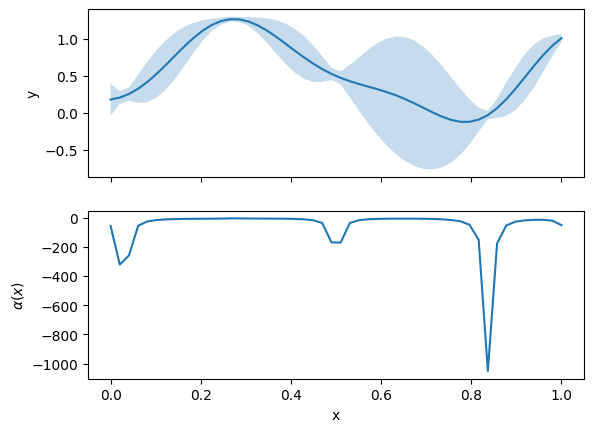

candidate: 0.2733182191520275 observation: 1.2829319145895433


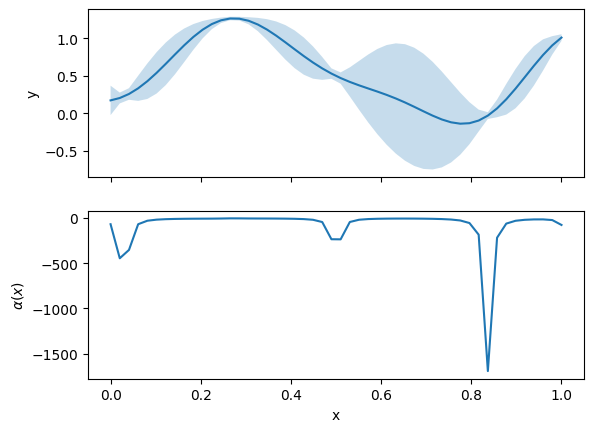

candidate: 0.2727046246367369 observation: 1.2675623583452544


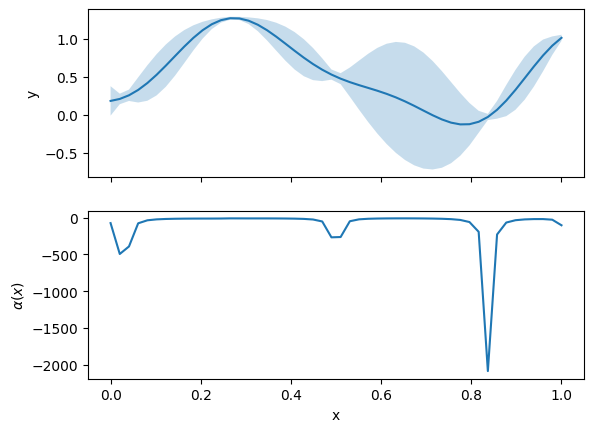

candidate: 0.6484686005046725 observation: -0.1637266953010096


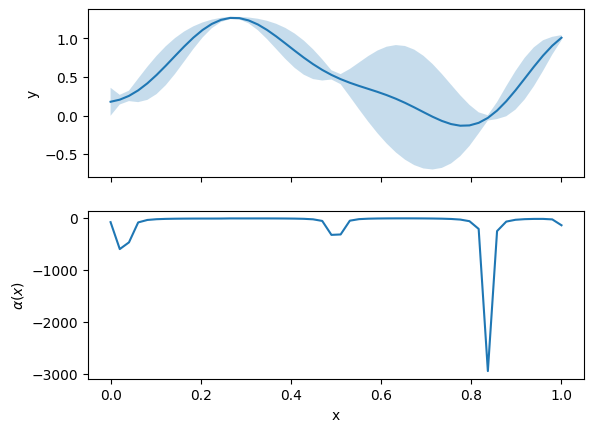

candidate: 1.0 observation: 1.0158131229620657


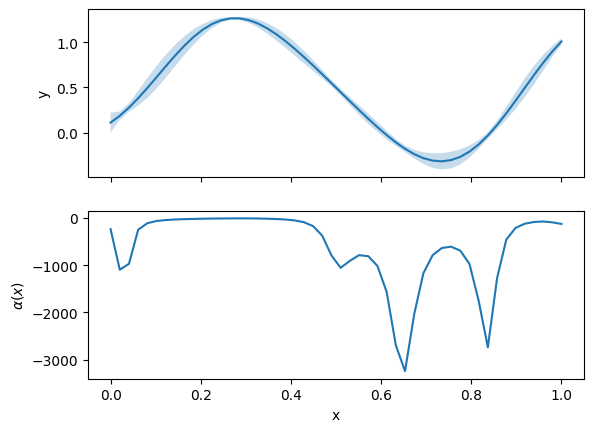

candidate: 0.0 observation: 0.0023975469566958896


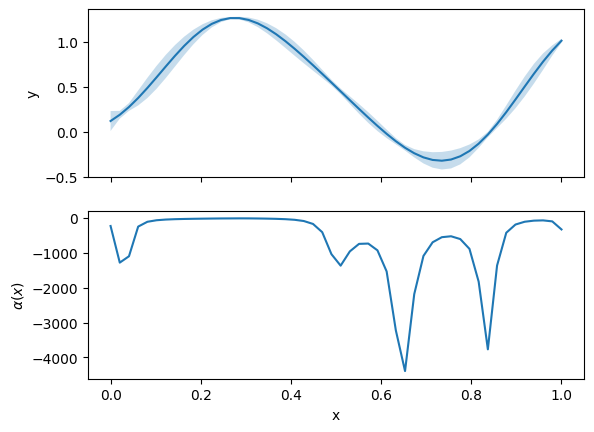

candidate: 0.2535956557825007 observation: 1.2543184447959672


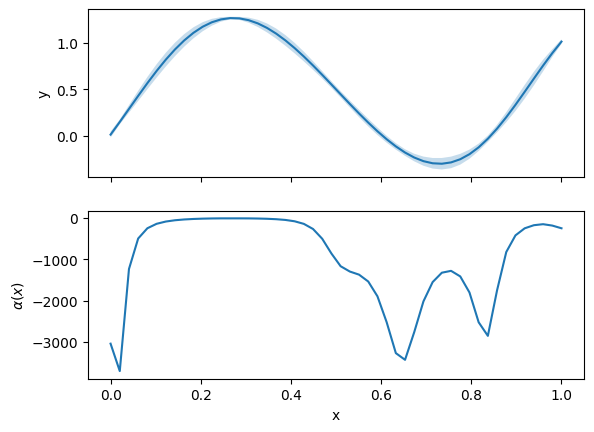

candidate: 0.29185358989749716 observation: 1.2488381766490693


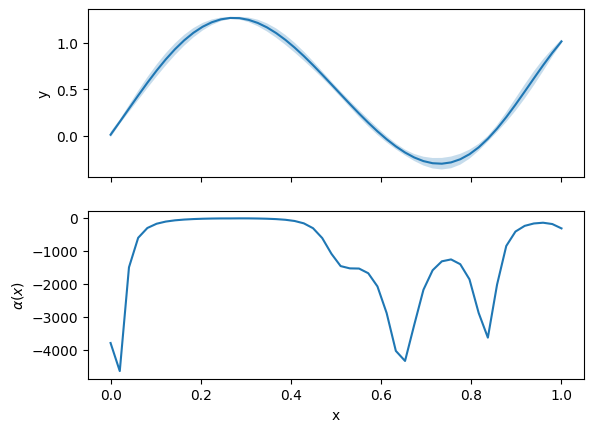

candidate: 0.25242434064213665 observation: 1.2443959506485487


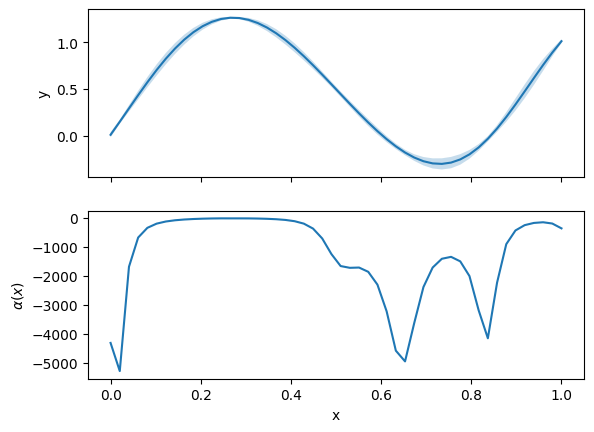

candidate: 0.294727626081336 observation: 1.2606398848290874


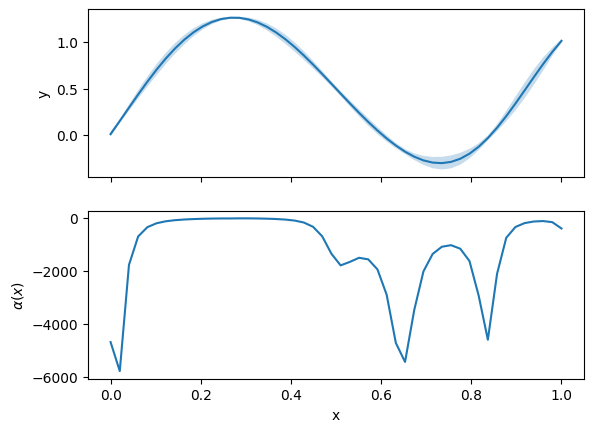

candidate: 0.29620957000596954 observation: 1.2570916086109947


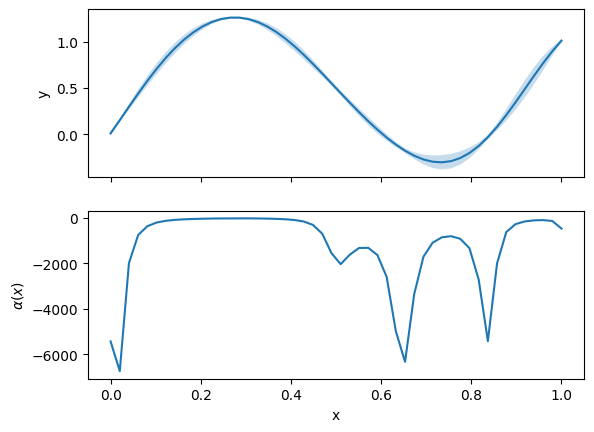

candidate: 0.2981654555673847 observation: 1.2551321122990393


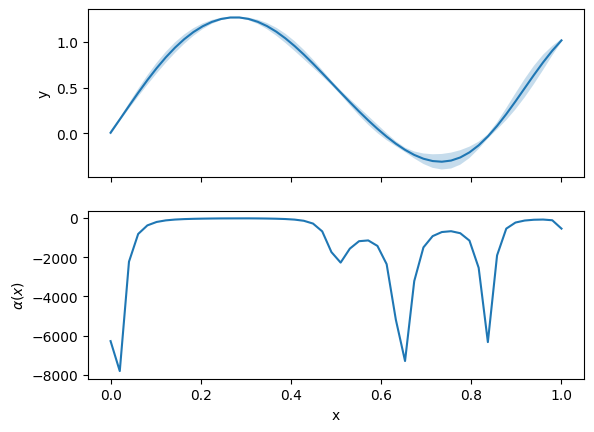

candidate: 0.30559368794446207 observation: 1.2400795883113513


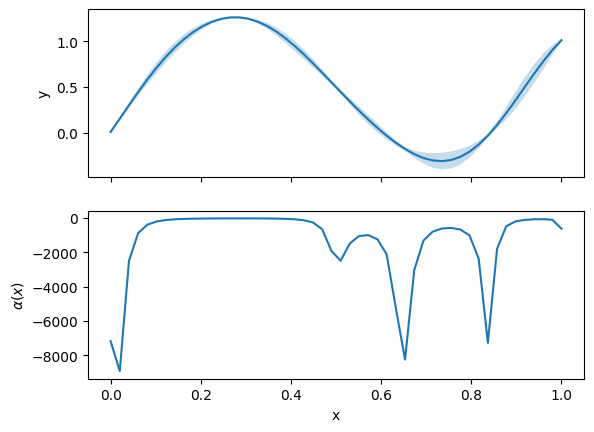

candidate: 0.266977733655383 observation: 1.2632190177205964


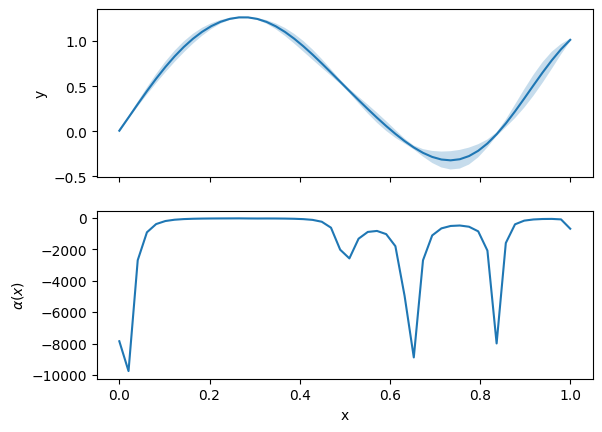

candidate: 0.9519026070157806 observation: 0.6532245952097897


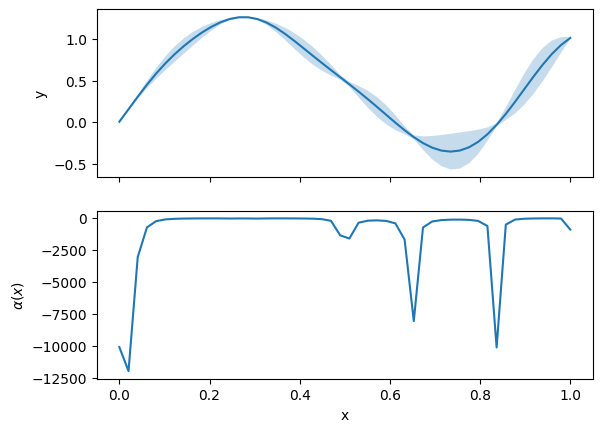

In [10]:
##### BEGIN SOLUTION
observations = []
for i in range(20):
    gp = SingleTaskGP(
        train_X=train_x,
        train_Y=train_y,
        input_transform=Normalize(d=1),
        outcome_transform=Standardize(m=1),
    )
    mll = ExactMarginalLogLikelihood(gp.likelihood, gp)
    fit_gpytorch_mll(mll)

    acquisition_function = LogExpectedImprovement(gp, best_f=torch.max(train_y))
    bounds = torch.stack([torch.zeros(1), torch.ones(1)]).to(torch.double)
    candidate, acq_value = optimize_acqf(
        acquisition_function, bounds=bounds, q=1, num_restarts=5, raw_samples=20,
    )

    train_x = torch.cat((train_x, candidate))
    f_val = f(candidate)
    train_y = torch.cat((train_y, f_val))

    print("candidate:", candidate.item(), "observation:", f_val.item())
    observations.append(f_val)

    # plot
    x = torch.linspace(0, 1, 50)
    with torch.no_grad():
        p = gp.posterior(x.reshape(-1,1,1))

        #get the mean
        m = p.mean.squeeze()

        #get the 2 sigma confidence region around the mean
        l,u = p.mvn.confidence_region()
        l = l.squeeze()
        u = u.squeeze()

        # calculate the acquisition function
        acqf = acquisition_function(x.reshape(-1,1,1))


    fig,ax = plt.subplots(2,1,sharex=True)
    ax[1].set_xlabel('x')
    ax[0].set_ylabel('y')
    #plot mean and confidence region
    ax[0].plot(x, m)
    ax[0].fill_between(x.squeeze(), l, u, alpha = 0.25, lw = 0)

    ax[1].plot(x, acqf)
    ax[1].set_ylabel(r"$\alpha(x)$")
    plt.show()

#### END SOLUTION

# Trust region BO

## **Task**
Rewrite the optimization loop above to set the acquisition function bounds centered at the location of the current optimum +/- 10\% of the input domain. Plot the objective function vs iteration for both cases. How does this affect optimization performance?

In [ ]:
train_x = torch.tensor([0.5],dtype=torch.double).unsqueeze(-1)
train_y = f(train_x)

candidate: 0.36225799973155404 observation: 1.140822823986036


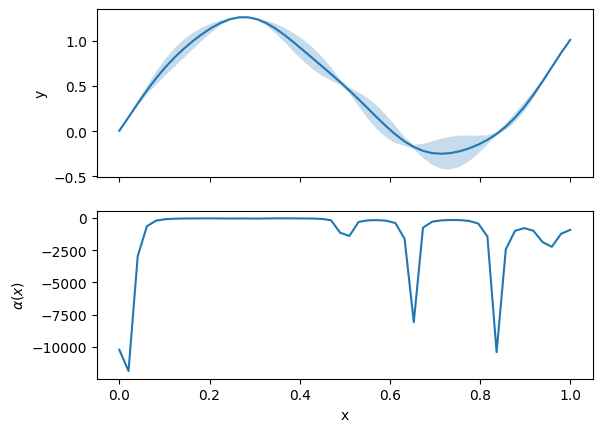

candidate: 0.2580852803863652 observation: 1.2601740202667613


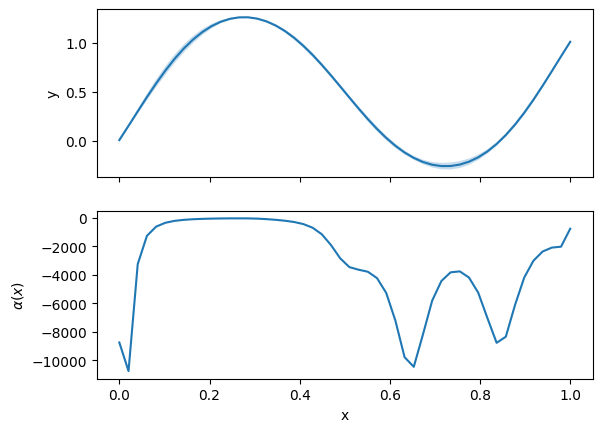

candidate: 0.2776469376446031 observation: 1.2640706215077533


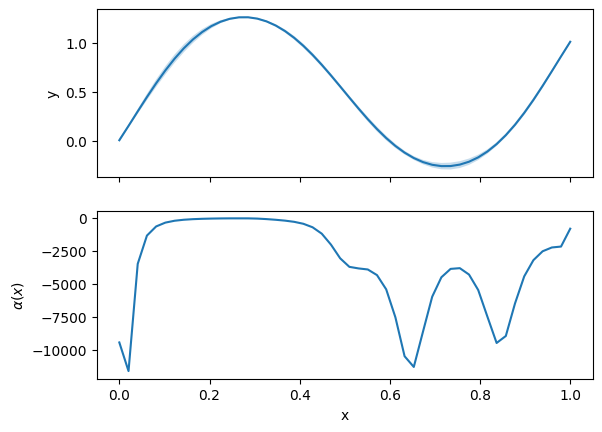

candidate: 0.24886103548667352 observation: 1.256978875136792


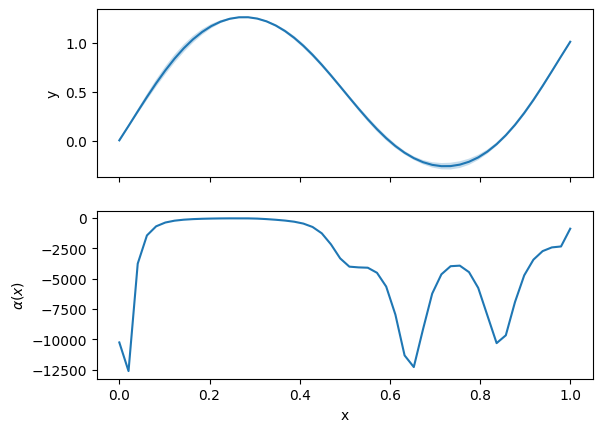

candidate: 0.2810295068003725 observation: 1.279159237546047


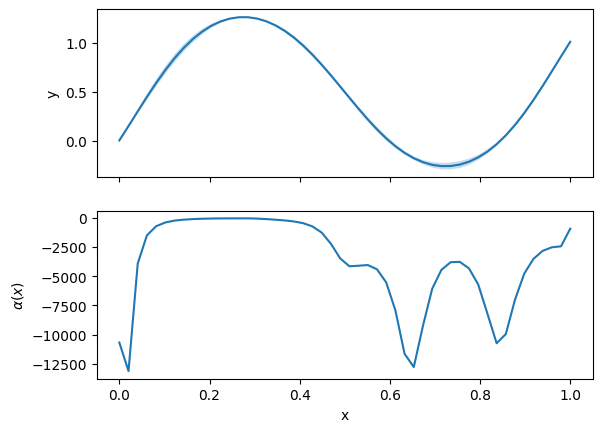

candidate: 0.28061853009526677 observation: 1.2763605229825368


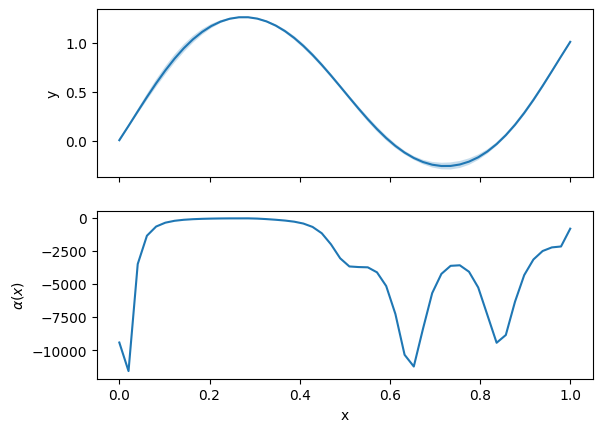

candidate: 0.28047741459237463 observation: 1.2704137587514257


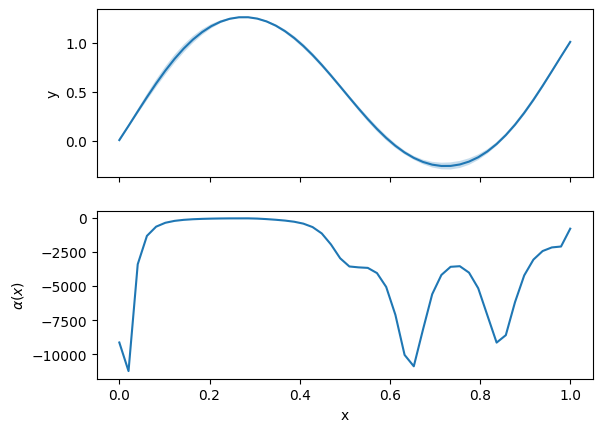

candidate: 0.28065044187194454 observation: 1.2555443332057699


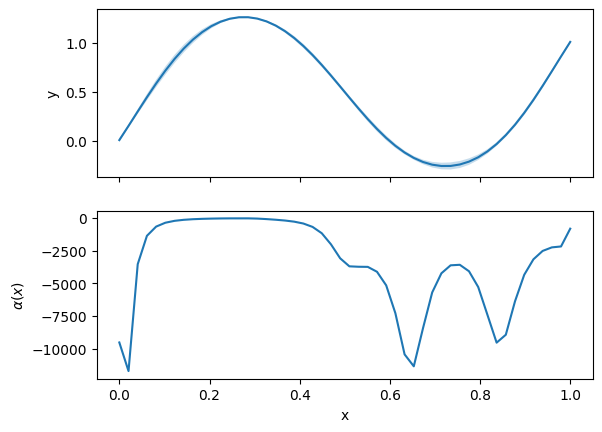

candidate: 0.2477339656944048 observation: 1.2640697248344943


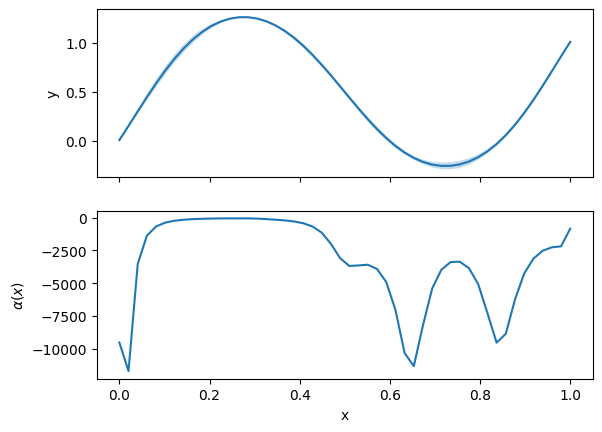

candidate: 0.245389588802008 observation: 1.2367292345747602


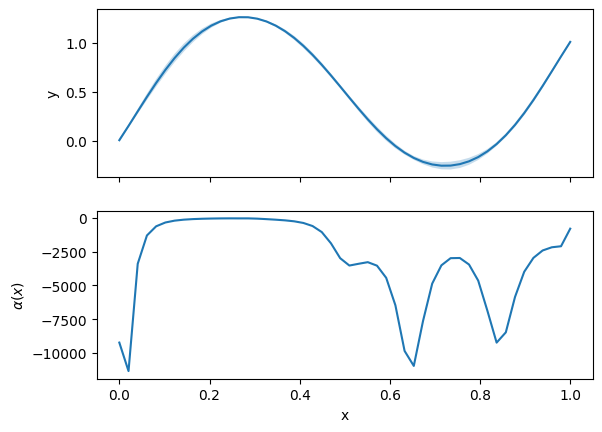

candidate: 0.28290427162003445 observation: 1.2564852992488387


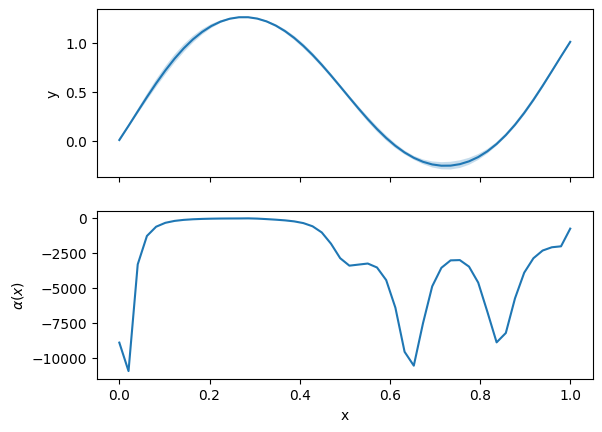

candidate: 0.28294466939603624 observation: 1.2681826588845502


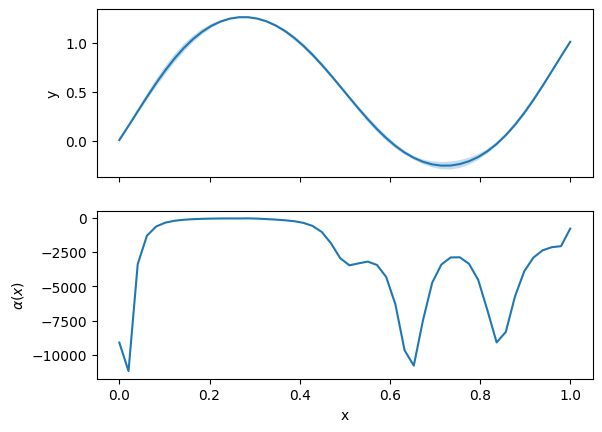

candidate: 0.282973118965247 observation: 1.2778605386398634


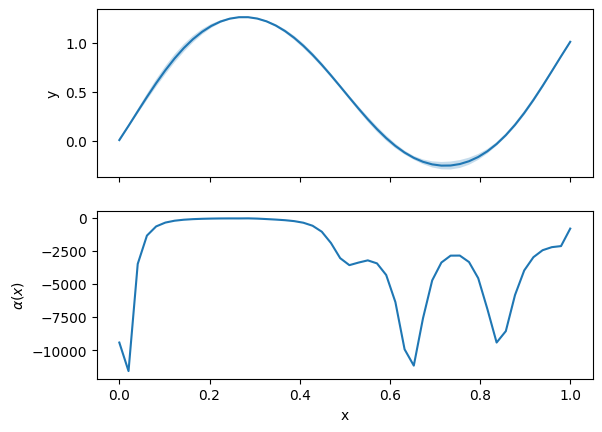

candidate: 0.2829726003409674 observation: 1.2560026435368168


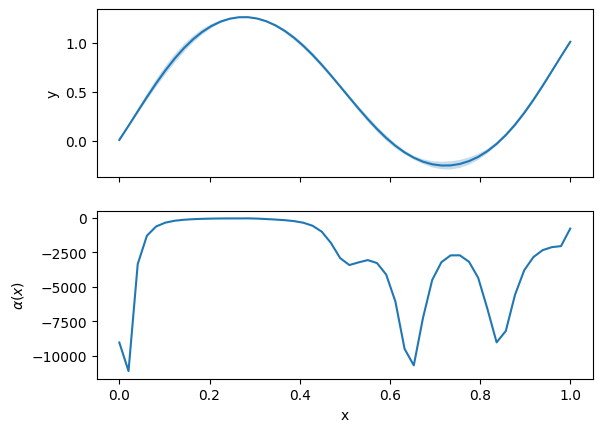

candidate: 0.28302236711672796 observation: 1.260829179326003


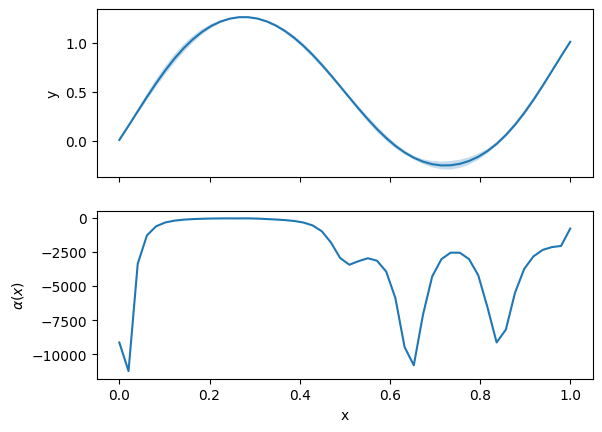

candidate: 0.24026174604923903 observation: 1.2429691530528544


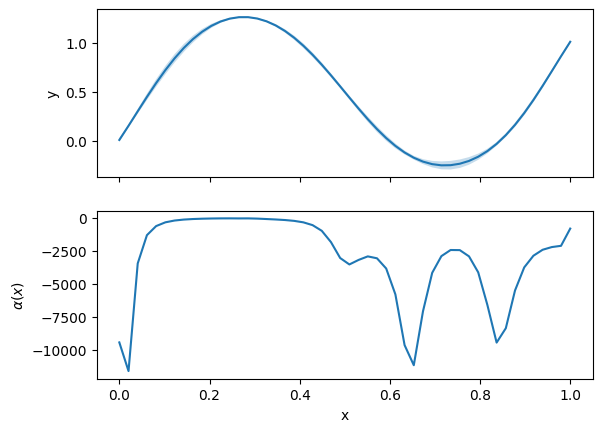

candidate: 0.28261590276989496 observation: 1.2597671635571526


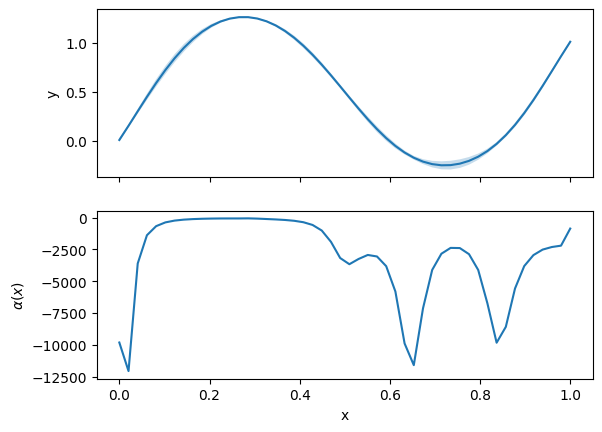

candidate: 0.2826206650976147 observation: 1.2629572313352464


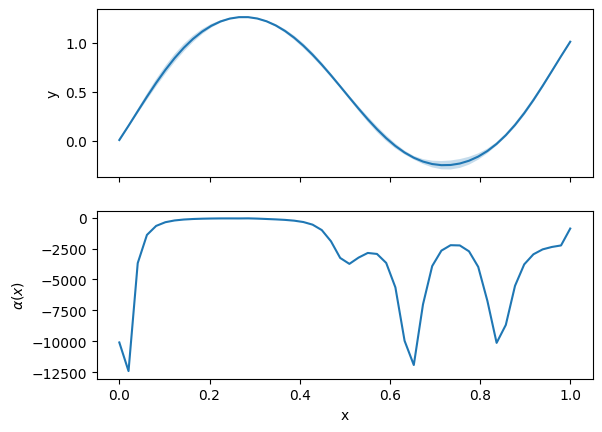

candidate: 0.2826212410443255 observation: 1.2718057023096343


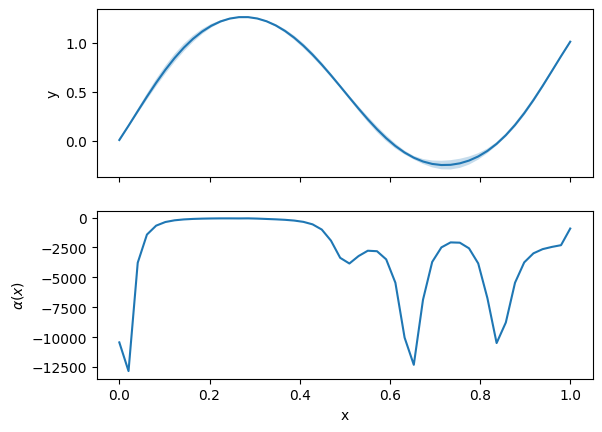

candidate: 0.17537552137180784 observation: 1.0648973424084738


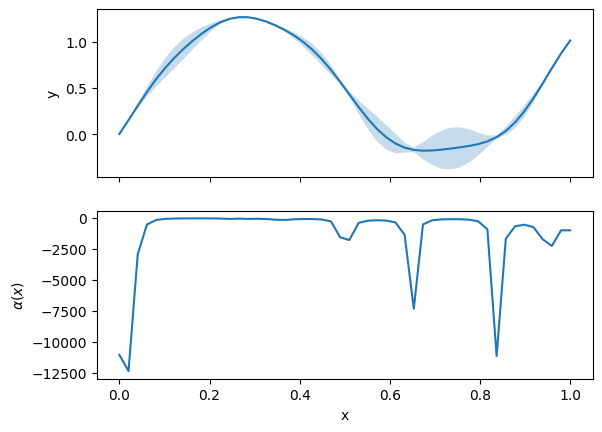

In [11]:
observations_bounded = []
for _ in range(20):
    gp = SingleTaskGP(
        train_X=train_x,
        train_Y=train_y,
        input_transform=Normalize(d=1),
        outcome_transform=Standardize(m=1),
    )
    mll = ExactMarginalLogLikelihood(gp.likelihood, gp)
    fit_gpytorch_mll(mll)

    acquisition_function = LogExpectedImprovement(gp, best_f=torch.max(train_y))

    best_x = train_x[torch.argmax(train_y)]
    bounds = torch.clip(torch.tensor((best_x - 0.1, best_x + 0.1)).unsqueeze(1),0,1)

    candidate, acq_value = optimize_acqf(
        acquisition_function, bounds=bounds, q=1, num_restarts=5, raw_samples=20,
    )

    train_x = torch.cat((train_x, candidate))
    f_val = f(candidate)
    train_y = torch.cat((train_y, f_val))

    print("candidate:", candidate.item(), "observation:", f_val.item())
    observations_bounded.append(f_val)

    # plot
    x = torch.linspace(0, 1, 50)
    with torch.no_grad():
        p = gp.posterior(x.reshape(-1,1,1))

        #get the mean
        m = p.mean.squeeze()

        #get the 2 sigma confidence region around the mean
        l,u = p.mvn.confidence_region()
        l = l.squeeze()
        u = u.squeeze()

        # calculate the acquisition function
        acqf = acquisition_function(x.reshape(-1,1,1))


    fig,ax = plt.subplots(2,1,sharex=True)
    ax[1].set_xlabel('x')
    ax[0].set_ylabel('y')
    #plot mean and confidence region
    ax[0].plot(x, m)
    ax[0].fill_between(x.squeeze(), l, u, alpha = 0.25, lw = 0)

    ax[1].plot(x, acqf)
    ax[1].set_ylabel(r"$\alpha(x)$")
    plt.show()

Text(0, 0.5, 'Objective function')

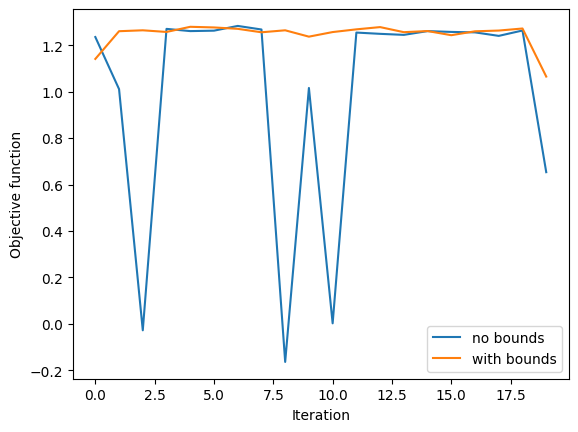

In [12]:
# plot objective function vs iteration number for both cases
fig, ax = plt.subplots()
ax.plot(torch.tensor(observations), label='no bounds')
ax.plot(torch.tensor(observations_bounded), label='with bounds')
ax.legend()
ax.set_xlabel("Iteration")
ax.set_ylabel("Objective function")

> **Your answer here** (How does this affect optimization performance?)

When bounding the acquisition function, there is a much stabler evaluation proceedure and a higher rate of convergence early on in the process.

 # **Homework**
Minimize the beamsize function defined in lab 1, using Xopt's `ExpectedImprovementGenerator`, defined for you below. Note that you can call `X.random_evaluate()` to generate random samples for creating the initial GP model.
  See https://xopt.xopt.org/examples/single_objective_bayes_opt/bo_tutorial/ for
  an example.

In [ ]:
from xopt.generators.bayesian import ExpectedImprovementGenerator
from xopt import VOCS

vocs = VOCS(
    variables={
        "k1": [0,15],
        "k2": [-15,0],
        "k3": [0, 15]
    },
    objectives={"beamsize": "MINIMIZE"}
)

generator = ExpectedImprovementGenerator(vocs=vocs)

In [ ]:
from cheetah.particles import ParameterBeam
from cheetah.accelerator import Drift, Quadrupole, Segment

incoming_beam = ParameterBeam.from_twiss(
  beta_x=torch.tensor(5.0),
  alpha_x=torch.tensor(0.0),
  emittance_x=torch.tensor(1e-8)
)

beamline = Segment(
  [
    Drift(length=torch.tensor(1.0)),
    Quadrupole(name="Q1",length=torch.tensor(0.1)),
    Drift(length=torch.tensor(1.0)),
    Quadrupole(name="Q2",length=torch.tensor(0.1)),
    Drift(length=torch.tensor(1.0)),
    Quadrupole(name="Q3",length=torch.tensor(0.1)),
    Drift(length=torch.tensor(1.0))
  ]
)

def calculate_beamsize(K, noise = 0.0):
  # set beamline parameters
  beamline.Q1.k1 = K[0]
  beamline.Q2.k1 = K[1]
  beamline.Q3.k1 = K[2]

  final_beam = beamline.track(incoming_beam)
  return (final_beam.sigma_x**2 + final_beam.sigma_y**2).sqrt() * 1e3 + noise * torch.randn(1)

def evaluate_beamsize(input_dict):
  K = torch.tensor(
      [input_dict['k1'], input_dict['k2'], input_dict['k3']]
  )
  return {
      'beamsize': calculate_beamsize(K).detach().numpy()
  }